# Stage 1 baseline-error diagnostics — pretrained leak detector

**Goal:** Test whether large Stage 1 healthy-spectrum residuals are associated with Stage 2 false alarms and missed leaks. Reuses the **exact original model classes, preprocessing, coordinates and pretrained checkpoints** from `leak_probability_validation.ipynb`. No retraining. Run all cells top to bottom.

Project paths: `data/2026-03-04/`, `models/`, `notebooks/`. Results: `data/stage1_diagnostics/`.

**Interpretation:** On *healthy* observations, Stage 1 residuals measure baseline reconstruction discrepancy (including sensor noise). During leaks, large residuals may be the intended signal and are **not automatically Stage 1 errors**. Associations do not prove causality. Validation run `1212_1` is not an independent test set.

In [14]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, average_precision_score,
                             roc_auc_score, brier_score_loss)

# USER CONFIGURATION
EXPERIMENT = "1212_1"          # original validation experiment; 1211_1 was training
WINDOW_SIZE = 40
BATCH_SIZE = 64               # reduce to 16 or 32 if memory constrained
THRESHOLD = 0.5               # NOT the author's optimized validation threshold
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROBE_ORDER = ["UUS", "US", "DS", "DDS"]

# Works whether Jupyter's working directory is project/notebooks or project/.
start = Path.cwd().resolve()
candidates = [start, start.parent]
PROJECT_ROOT = next((p for p in candidates
                     if (p / "data" / "2026-03-04").is_dir() and (p / "models").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find project root from {start}. Expected data/2026-03-04 and models/ "
        "under the working directory or its parent."
    )
DATA_DIR = PROJECT_ROOT / "data" / "2026-03-04"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "results" / "stage1_diagnostics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_PATH = MODELS_DIR / "leak_detect_baseline.pt"
RESIDUAL_PATH = MODELS_DIR / "leak_detect_residual.pt"

for path in [BASELINE_PATH, RESIDUAL_PATH] + [DATA_DIR / f"{p}{EXPERIMENT}.csv" for p in PROBE_ORDER]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required file: {path}")
print("Project:", PROJECT_ROOT)
print("Data:", DATA_DIR)
print("Device:", DEVICE)
print("Output:", OUTPUT_DIR)

Project: /home/ubuntu/notebooks/Leak_Detection
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04
Device: cpu
Output: /home/ubuntu/notebooks/Leak_Detection/results/stage1_diagnostics


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class BaselineSpectralModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        re_feat_dim=16,
        coord_feat_dim=16
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.re_feat_dim = re_feat_dim
        self.coord_feat_dim = coord_feat_dim

        self.re_embed = nn.Sequential(
            nn.Linear(1, re_feat_dim),
            nn.ReLU()
        )

        self.coord_embed = nn.Sequential(
            nn.Linear(2, coord_feat_dim),
            nn.ReLU()
        )

        self.re_lstm = nn.LSTM(
            input_size=re_feat_dim + coord_feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.re_to_spec = nn.Linear(hidden_dim, Freq)

    def forward(self, X_window, Re_window, coords):

        B, W, P, F = X_window.shape
        assert F == self.Freq

        # Build per-probe inputs in batched form
        re_p = Re_window.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, P, 1)   # (B,W,P,1)
        coord_p = coords.unsqueeze(1).expand(-1, W, -1, -1)                  # (B,W,P,2)

        re_feat = self.re_embed(re_p)                                         # (B,W,P,Cr)
        coord_feat = self.coord_embed(coord_p)                                # (B,W,P,Cc)

        probe_in = torch.cat([re_feat, coord_feat], dim=-1)                   # (B,W,P,Cr+Cc)

        # Move P into batch: (B,W,P,D) -> (B*P,W,D)
        D = probe_in.shape[-1]
        probe_in = probe_in.permute(0, 2, 1, 3).contiguous()                  # (B,P,W,D)
        probe_in = probe_in.view(B * P, W, D)                                 # (B*P,W,D)

        # Shared LSTM over each probe independently
        probe_feats, _ = self.re_lstm(probe_in)                               # (B*P,W,H)

        # Reshape back: (B*P,W,H) -> (B,W,P,H)
        H = probe_feats.shape[-1]
        probe_feats = probe_feats.view(B, P, W, H)                            # (B,P,W,H)
        probe_feats = probe_feats.permute(0, 2, 1, 3).contiguous()            # (B,W,P,H)

        X_hat = self.re_to_spec(probe_feats)                                  # (B,W,P,F)

        return {"baseline": X_hat}

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ProbeFrequencyUpdateBlock(nn.Module):
    def __init__(self, feat_dim, hidden_dim=64, dropout=0.1):
        super().__init__()
        self.feat_dim = feat_dim

        self.gate_mlp = nn.Sequential(
            nn.Linear(2 * feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        self.out_dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(feat_dim)

    def forward(self, h_pre, return_stats=False):

        B_graph, P, D = h_pre.shape
        assert D == self.feat_dim, f"Expected feat_dim={self.feat_dim}, got {D}"

        hi = h_pre.unsqueeze(2).expand(B_graph, P, P, D)
        hj = h_pre.unsqueeze(1).expand(B_graph, P, P, D)

        diff = hj - hi
        abs_diff = torch.abs(diff)

        edge_feat = torch.cat([diff, abs_diff], dim=-1)
        gate = torch.sigmoid(self.gate_mlp(edge_feat))

        eye = torch.eye(P, device=h_pre.device).view(1, P, P, 1)
        gate = gate * (1.0 - eye)

        msg = diff * gate
        denom = gate.sum(dim=2).clamp_min(1e-6)
        agg = msg.sum(dim=2) / denom

        h_post = self.norm(self.out_dropout(agg))

        if return_stats:
            stats = {
                "gate_mean": gate.mean().detach(),
                "gate_matrix": gate.squeeze(-1).detach(),
                "agg_abs_mean": agg.abs().mean().detach(),
                "agg_norm": agg.norm(dim=-1).mean().detach(),
                "h_post_abs_mean": h_post.abs().mean().detach(),
                "h_post_norm": h_post.norm(dim=-1).mean().detach(),
            }
            return h_post, stats

        return h_post


class ResidualLSTMFrequencyGraphLeakNet(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        tf_hidden_dim=64,
        graph_hidden_dim=64,
        readout_hidden_dim=64,
        num_lstm_layers=1,
        dropout=0.1,
        weight_temperature=2.0,
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.weight_temperature = weight_temperature


        # Per-probe temporal encoder
        self.lstm = nn.LSTM(
            input_size=Freq,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=0.0 if num_lstm_layers == 1 else dropout
        )

        # Decode hidden temporal features back into frequency space.
        self.decode_freq = nn.Sequential(
            nn.Linear(hidden_dim, tf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(tf_hidden_dim, Freq)
        )

        self.summary_dim = 3 * Freq

        self.freq_block_dim = 3
        self.readout_block_dim = 6
        self.readout_dim = self.readout_block_dim * Freq 

        # Frequency-wise graph block
        self.gnn = ProbeFrequencyUpdateBlock(
            feat_dim=self.freq_block_dim,
            hidden_dim=graph_hidden_dim,
            dropout=dropout
        )

        # Probe-frequency score head
        self.probe_freq_score_head = nn.Sequential(
            nn.Linear(self.readout_block_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )


        # Optional diagnostic per-probe heads
        self.probe_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.probe_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        # Global heads
        self.global_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.global_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

    def _time_summary(self, x):

        x_mean = x.mean(dim=1)
        x_max = x.max(dim=1).values
        x_last = x[:, -1, :]

        return torch.cat([x_mean, x_max, x_last], dim=-1)

    def _reshape_summary_to_frequency_blocks(self, h_pre, B, P, Freq):
        h_pre_freq = h_pre.view(B, P, 3, Freq)
        h_pre_freq = h_pre_freq.permute(0, 1, 3, 2).contiguous()
        return h_pre_freq

    def _flatten_frequency_readout(self, h_readout_freq, B, P, Freq):

        h_readout = (
            h_readout_freq
            .permute(0, 1, 3, 2)    
            .contiguous()
            .view(B, P, 6 * Freq) 
        )
        return h_readout

    def _flatten_h_post_freq(self, h_post_freq, B, P, Freq):

        h_post = (
            h_post_freq
            .permute(0, 1, 3, 2)   
            .contiguous()
            .view(B, P, 3 * Freq)    
        )
        return h_post

    def _build_global_from_frequency_blocks(self, h_readout_freq):

        B, P, Freq, C = h_readout_freq.shape
        assert C == self.readout_block_dim, (
            f"Expected block dim={self.readout_block_dim}, got {C}"
        )

        # Score each probe-frequency block
        probe_freq_scores = self.probe_freq_score_head(h_readout_freq).squeeze(-1)

        # Independent sigmoid gates
        probe_freq_weights = torch.sigmoid(probe_freq_scores)

        # P-scaled weighted sum across probes
        h_global_freq = torch.sum(
            probe_freq_weights.unsqueeze(-1) * h_readout_freq,
            dim=1
        ) / P

        # Flatten back to (B, 6F)
        h_global = (
            h_global_freq
            .permute(0, 2, 1)
            .contiguous()
            .view(B, self.readout_block_dim * Freq)
        )

        # Diagnostic scalar per frequency
        h_global_scores = torch.sum(
            probe_freq_weights * probe_freq_scores,
            dim=1
        ) / P

        return (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        )

    def forward(
        self,
        residual_window,
        probe_coords=None,
        disable_gnn=False,
        return_gnn_stats=False,
    ):

        B, W, P, Freq = residual_window.shape
        assert Freq == self.Freq, f"Expected Freq={self.Freq}, got {Freq}"

        # Encode each probe independently through the LSTM
        x = residual_window.permute(0, 2, 1, 3).contiguous()
        x = x.view(B * P, W, Freq)

        lstm_out_raw, _ = self.lstm(x)    
        decoded_freq_raw = self.decode_freq(lstm_out_raw)  

        # Build mean / max / last time summary
        decoded_summary_raw = self._time_summary(decoded_freq_raw)
        h_pre = decoded_summary_raw.view(B, P, self.summary_dim)

        # Reshape into frequency-wise blocks
        h_pre_freq = self._reshape_summary_to_frequency_blocks(h_pre, B, P, Freq)

        # Graph each frequency across probes
        gnn_stats = None

        if not disable_gnn:
            h_for_gnn = h_pre_freq.permute(0, 2, 1, 3).contiguous()
            h_for_gnn = h_for_gnn.view(B * Freq, P, self.freq_block_dim)

            if return_gnn_stats:
                h_post_graph, gnn_stats = self.gnn(h_for_gnn, return_stats=True)
            else:
                h_post_graph = self.gnn(h_for_gnn)

            h_post_freq = h_post_graph.view(B, Freq, P, self.freq_block_dim)
            h_post_freq = h_post_freq.permute(0, 2, 1, 3).contiguous()
        else:
            h_post_freq = h_pre_freq

        # Flatten graph output for diagnostics
        h_post = self._flatten_h_post_freq(h_post_freq, B, P, Freq)

        # Build frequency-wise readout
        h_readout_freq = torch.cat([h_pre_freq, h_post_freq], dim=-1)

        # Flatten for optional diagnostic per-probe heads
        h_readout = self._flatten_frequency_readout(h_readout_freq, B, P, Freq)

        # Optional per-probe diagnostics
        probe_leak_logits = self.probe_leak_head(h_readout).squeeze(-1)
        probe_leak_probs = torch.sigmoid(probe_leak_logits)

        probe_mag_raw = self.probe_mag_head(h_readout).squeeze(-1)
        probe_mag_base = F.softplus(probe_mag_raw)

        # Build global vector from frequency-wise probe pooling
        (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        ) = self._build_global_from_frequency_blocks(h_readout_freq)

        # Global leak probability and magnitude
        leak_logit = self.global_leak_head(h_global).squeeze(-1)
        leak_prob = torch.sigmoid(leak_logit)

        mag_base = F.softplus(self.global_mag_head(h_global).squeeze(-1))

        magnitude = mag_base * leak_prob.detach()

        # Reshape LSTM outputs for diagnostics
        H = lstm_out_raw.shape[-1]

        lstm_out = (
            lstm_out_raw
            .view(B, P, W, H)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_freq = (
            decoded_freq_raw
            .view(B, P, W, Freq)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_summary = decoded_summary_raw.view(B, P, self.summary_dim)

        out = {
            # Final predictions
            "leak_logit": leak_logit,      # (B,)
            "leak_prob": leak_prob,        # (B,)
            "magnitude": magnitude,        # (B,)
            "mag_base": mag_base,          # (B,)

            # Main global representation
            "h_global": h_global,              # (B, 6F)
            "h_global_freq": h_global_freq,    # (B, F, 6)
            "h_global_scores": h_global_scores,# (B, F)

            # Frequency-wise graph / pooling diagnostics
            "h_pre_freq": h_pre_freq,                  # (B, P, F, 3)
            "h_post_freq": h_post_freq,                # (B, P, F, 3)
            "h_readout_freq": h_readout_freq,          # (B, P, F, 6)
            "probe_freq_scores": probe_freq_scores,    # (B, P, F)
            "probe_freq_weights": probe_freq_weights,  # (B, P, F)

            # Flattened diagnostics
            "h_pre": h_pre,                  # (B, P, 3F)
            "h_post": h_post,                # (B, P, 3F)
            "h_readout": h_readout,          # (B, P, 6F)

            # LSTM / decoded frequency diagnostics
            "lstm_out": lstm_out,                    # (B, W, P, H)
            "decoded_freq": decoded_freq,            # (B, W, P, F)
            "decoded_summary": decoded_summary,      # (B, P, 3F)

            # Optional per-probe diagnostic heads
            "probe_leak_logits": probe_leak_logits,  # (B, P)
            "probe_leak_probs": probe_leak_probs,    # (B, P)
            "probe_mag_base": probe_mag_base,        # (B, P)
        }

        if return_gnn_stats:
            out["gnn_stats"] = gnn_stats

        return out

In [4]:
PROBE_COORDS = {
    "1212_1": {
        "UUS": [-4.1275, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [3.0226, 0.0250],
    },
}
HOLE_SIZES = {"1212_1": 4.0, "1211_1": 2.0}


def read_sensor_csv(path):
    df = pd.read_csv(path, low_memory=False)
    if len(df.columns) == 1:
        raise ValueError(f"Only one column found in {path.name}; check CSV delimiter/format.")
    df.columns = [str(c).strip() for c in df.columns]
    return df


def load_experiment(experiment):
    if experiment not in PROBE_COORDS:
        raise ValueError(f"Coordinates not configured for experiment {experiment}")
    dfs = {p: read_sensor_csv(DATA_DIR / f"{p}{experiment}.csv") for p in PROBE_ORDER}

    # Match the original frequency extraction: e.g. '...ǀf1000' -> 'f1000'.
    def frequency_map(df):
        result = {}
        for col in df.columns:
            if "ǀf" in col:
                label = col.split("ǀ")[1]
                if re.fullmatch(r"f[0-9]+(?:_[0-9]+)?", label):
                    result[label] = col
        return result

    freq_maps = {p: frequency_map(df) for p, df in dfs.items()}
    common_freqs = sorted(set.intersection(*(set(m) for m in freq_maps.values())),
                          key=lambda s: float(s[1:].replace("_", ".")))
    if len(common_freqs) != 27:
        raise ValueError(f"Expected 27 common frequencies; found {len(common_freqs)}: {common_freqs}")

    # Original notebook picks a reference dataframe from the grouped probe list.
    # Here use UUS explicitly and check alignment across all probes.
    ref = dfs["UUS"]
    time_col = "Date-Time"
    leak_col = "Leak Event"
    if time_col not in ref or leak_col not in ref:
        raise KeyError(f"Expected columns {time_col!r}, {leak_col!r} in UUS file; got {list(ref.columns)}")
    re_col = next((c for c in ref.columns if "Re" in c or "re" in c), None)
    if re_col is None:
        raise KeyError("No Reynolds-number column found (original notebook searches for 'Re' or 're').")

    min_T = min(len(df) for df in dfs.values())
    if len(set(len(df) for df in dfs.values())) != 1:
        print("WARNING: Unequal sensor lengths; truncating all to", min_T, "(original notebook behavior).")
    time = pd.to_datetime(ref[time_col].iloc[:min_T], errors="raise")
    if time.isna().any():
        raise ValueError("Missing timestamps in reference file")
    for p in PROBE_ORDER[1:]:
        other_time = pd.to_datetime(dfs[p][time_col].iloc[:min_T], errors="raise")
        if not np.array_equal(time.to_numpy(), other_time.to_numpy()):
            raise ValueError(f"Timestamps are not aligned between UUS and {p}. Do not infer on misaligned sensors.")
        if leak_col in dfs[p]:
            a = pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            b = pd.to_numeric(dfs[p][leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            if not np.array_equal(a, b):
                raise ValueError(f"Leak Event labels disagree between UUS and {p}")

    values = []
    for p in PROBE_ORDER:
        columns = [freq_maps[p][f] for f in common_freqs]
        x = dfs[p][columns].iloc[:min_T].apply(pd.to_numeric, errors="coerce").fillna(0.0)
        values.append(x.to_numpy(dtype=np.float32))
    X_raw = np.stack(values, axis=1)     # (T, 4, 27)
    re_raw = pd.to_numeric(ref[re_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy(dtype=np.float32)
    leak = (pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0).astype(np.float32)
    coords = np.array([PROBE_COORDS[experiment][p] for p in PROBE_ORDER], dtype=np.float32)

    return {
        "iteration": experiment,
        "X": torch.from_numpy(X_raw / 50.0),  # exact original normalization
        "Re": torch.from_numpy(re_raw / 150.0),
        "coords": torch.from_numpy(coords),
        "leak_open": leak,
        "datetime": time.to_numpy(),
        "frequency_labels": common_freqs,
        "re_column": re_col,
        "raw_rows": min_T,
    }

sample = load_experiment(EXPERIMENT)
print(f"Experiment: {EXPERIMENT}; observations: {sample['raw_rows']:,}; "
      f"windows: {sample['raw_rows']-WINDOW_SIZE+1:,}")
print("Reynolds column:", sample["re_column"])
print("Frequencies:", sample["frequency_labels"])
print("True leak proportion:", round(float(sample["leak_open"].mean()), 4))

Experiment: 1212_1; observations: 10,801; windows: 10,762
Reynolds column: RNo-StepǀReynolds
Frequencies: ['f25', 'f31_5', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000']
True leak proportion: 0.2778


In [5]:
# State dictionaries saved by torch.save(model.state_dict(), path), as in the original notebook.
# weights_only=True is preferred for security (PyTorch >=2.0); fall back for older versions.
def load_weights(path):
    try:
        obj = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        obj = torch.load(path, map_location="cpu")
    if not isinstance(obj, dict):
        raise TypeError(f"{path.name} is not a state dictionary")
    if "state_dict" in obj and isinstance(obj["state_dict"], dict):
        obj = obj["state_dict"]
    return obj

baseline_model = BaselineSpectralModel(Freq=27, hidden_dim=64, re_feat_dim=16, coord_feat_dim=16)
residual_model = ResidualLSTMFrequencyGraphLeakNet(
    Freq=27, hidden_dim=64, tf_hidden_dim=64,
    graph_hidden_dim=64, readout_hidden_dim=64,
    num_lstm_layers=1, dropout=0.1,
)
baseline_model.load_state_dict(load_weights(BASELINE_PATH), strict=True)
residual_model.load_state_dict(load_weights(RESIDUAL_PATH), strict=True)
baseline_model = baseline_model.to(DEVICE).eval()
residual_model = residual_model.to(DEVICE).eval()
print("Loaded:", BASELINE_PATH.name, "and", RESIDUAL_PATH.name)

Loaded: leak_detect_baseline.pt and leak_detect_residual.pt


## 1. Inference with Stage 1 diagnostics

For each 40-step window, calculate the original Stage 1 baseline and Stage 2 probability. Save **endpoint residuals** (one per timestamp, probe, frequency) and **whole-window residual summaries** (the exact window fed into Stage 2). All spectral residuals below are in **original amplitude units**, multiplying the notebook's `/50` normalization back by 50. This is an analysis convention only; model inference remains unchanged.

In [6]:
@torch.inference_mode()
def infer_with_stage1_diagnostics(sample, window_size=40, batch_size=64):
    X, Re = sample["X"], sample["Re"]
    coords = sample["coords"].unsqueeze(0).to(DEVICE)
    T, P, F = X.shape
    X_windows = X.unfold(0, window_size, 1).permute(0, 3, 1, 2).contiguous()
    Re_windows = Re.unfold(0, window_size, 1)
    rows, endpoint_residuals = [], []
    for first in range(0, len(X_windows), batch_size):
        Xw = X_windows[first:first+batch_size].to(DEVICE)
        Rew = Re_windows[first:first+batch_size].to(DEVICE)
        cb = coords.expand(len(Xw), -1, -1)
        baseline = baseline_model(Xw, Rew, cb)["baseline"]
        residual = Xw - baseline
        prob = residual_model(residual, cb)["leak_prob"].detach().cpu().numpy().reshape(-1)
        # Restore original amplitude units for diagnostics; model receives normalized residuals.
        endpoint = (residual[:, -1] * 50.0).detach().cpu().numpy()  # (B,P,F)
        window = (residual * 50.0)
        win_rmse = window.square().mean(dim=(1,2,3)).sqrt().cpu().numpy()
        win_meanabs = window.abs().mean(dim=(1,2,3)).cpu().numpy()
        win_maxabs = window.abs().amax(dim=(1,2,3)).cpu().numpy()
        endpoint_residuals.append(endpoint)
        for j in range(len(Xw)):
            e = first + j + window_size - 1
            rr = endpoint[j]
            rows.append({
                "observation_index": e+1,
                "datetime": pd.to_datetime(sample["datetime"][e]),
                "true_leak": int(sample["leak_open"][e]),
                "predicted_leak_probability": float(prob[j]),
                "Reynolds": float(Re[e]) * 150.0,
                "endpoint_residual_rmse": float(np.sqrt(np.mean(rr**2))),
                "endpoint_residual_mean_abs": float(np.mean(np.abs(rr))),
                "endpoint_residual_max_abs": float(np.max(np.abs(rr))),
                "window_residual_rmse": float(win_rmse[j]),
                "window_residual_mean_abs": float(win_meanabs[j]),
                "window_residual_max_abs": float(win_maxabs[j]),
            })
    result = pd.DataFrame(rows)
    result["delta_Reynolds"] = result["Reynolds"].diff().fillna(0)
    result["abs_delta_Reynolds"] = result["delta_Reynolds"].abs()
    result["predicted_leak"] = (result["predicted_leak_probability"] >= THRESHOLD).astype(int)
    conditions = [
        (result.true_leak.eq(0) & result.predicted_leak.eq(0)),
        (result.true_leak.eq(0) & result.predicted_leak.eq(1)),
        (result.true_leak.eq(1) & result.predicted_leak.eq(0)),
        (result.true_leak.eq(1) & result.predicted_leak.eq(1)),
    ]
    result["error_type"] = np.select(conditions, ["TN","FP","FN","TP"], default="unknown")
    return result, np.concatenate(endpoint_residuals, axis=0)

results, endpoint_residuals = infer_with_stage1_diagnostics(sample, WINDOW_SIZE, BATCH_SIZE)
assert len(results) == len(endpoint_residuals)
print(results.error_type.value_counts().to_string())
print("Rows:", len(results), "Endpoint residual array:", endpoint_residuals.shape)
display(results.head())

error_type
TN    7286
TP    1740
FN    1260
FP     476
Rows: 10762 Endpoint residual array: (10762, 4, 27)


,observation_index,datetime,true_leak,predicted_leak_probability,Reynolds,endpoint_residual_rmse,endpoint_residual_mean_abs,endpoint_residual_max_abs,window_residual_rmse,window_residual_mean_abs,window_residual_max_abs,delta_Reynolds,abs_delta_Reynolds,predicted_leak,error_type
0,40,2023-12-12 16:00:39,0,0.000003,13.312500,2.096570,1.416646,10.025695,2.267356,1.485667,19.745430,0.000000,0.000000,0,TN
1,41,2023-12-12 16:00:40,0,0.000005,13.333333,2.099406,1.374871,10.238406,2.267862,1.483476,19.746181,0.020833,0.020833,0,TN
2,42,2023-12-12 16:00:41,0,0.000006,13.354167,2.340524,1.500045,13.526949,2.271804,1.483464,19.747066,0.020834,0.020834,0,TN
3,43,2023-12-12 16:00:42,0,0.000008,13.375000,2.005358,1.283952,12.049493,2.259380,1.475491,19.748030,0.020833,0.020833,0,TN
4,44,2023-12-12 16:00:43,0,0.000012,13.395832,2.210144,1.438880,12.983788,2.251889,1.468443,19.748819,0.020833,0.020833,0,TN


## 2. Healthy baseline error: false positives versus true negatives

Healthy-only comparisons are the most defensible measure of Stage 1 baseline quality. A higher FP residual distribution is consistent with Stage 1 contributing to false alarms, but could also reflect legitimate healthy acoustic variation that Stage 2 interprets incorrectly. No p-values are computed from overlapping windows, which are not independent.

endpoint_residual_rmse                          \
                            count    mean  median     std   
error_type                                                  
FN                           1260  2.1957  2.1358  0.3959   
FP                            476  2.3634  2.3193  0.3359   
TN                           7286  2.3992  2.2274  0.6095   
TP                           1740  2.3113  2.2711  0.3375   

           endpoint_residual_mean_abs                          \
                                count    mean  median     std   
error_type                                                      
FN                               1260  1.4344  1.3983  0.2617   
FP                                476  1.5597  1.5446  0.2291   
TN                               7286  1.6263  1.5106  0.4366   
TP                               1740  1.5208  1.4988  0.2313   

           window_residual_rmse          ... window_residual_mean_abs          \
                          count    mean  ...                   median     std   
error_type                               ...                                    
FN                         1260  2.2201  ...                   1.4139  0.1188   
FP                          476  2.3749  ...                   1.5514  0.1494   
TN                         7286  2.4228  ...                   1.5286  0.2900   
TP                         1740  2.3402  ...                   1.5266  0.1239   

           abs_delta_Reynolds                          \
                        count    mean  median     std   
error_type                                              
FN                       1260  0.0000  0.0000  0.0000   
FP                        476  0.0778  0.0417  0.0733   
TN                       7286  0.0343  0.0000  0.0460   
TP                       1740  0.0000  0.0000  0.0000   

           predicted_leak_probability                          
                                count    mean  median     std  
error_type                                                     
FN                               1260  0.0621  0.0045  0.1150  
FP                                476  0.8861  0.9608  0.1483  
TN                               7286  0.0108  0.0001  0.0496  
TP                               1740  0.9478  0.9949  0.1077  

[4 rows x 24 columns]

Healthy FP count: 476 TN count: 7286
endpoint_residual_rmse: FP median=2.3193, TN median=2.2274, FP/TN ratio=1.041
window_residual_rmse: FP median=2.3566, TN median=2.2370, FP/TN ratio=1.053


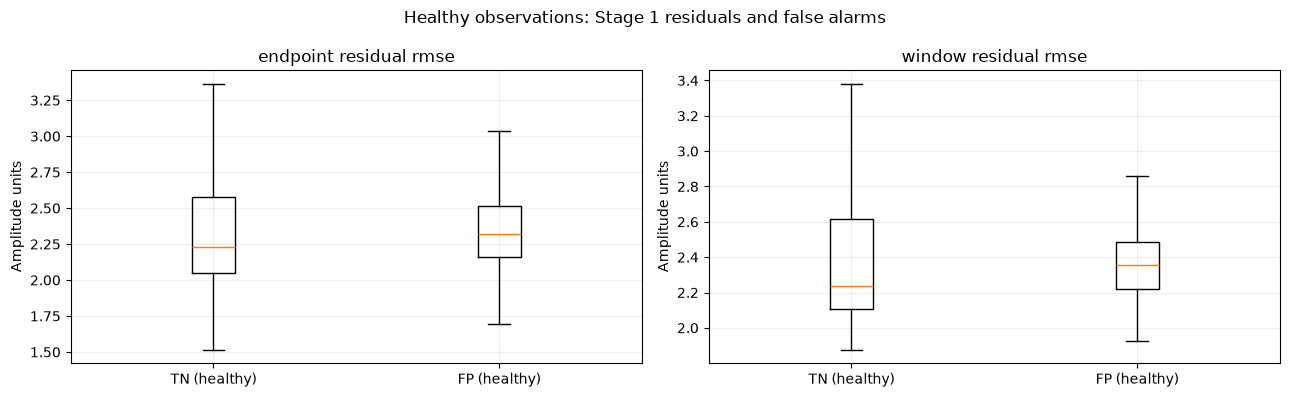

In [7]:
diagnostics = ["endpoint_residual_rmse", "endpoint_residual_mean_abs", "window_residual_rmse", "window_residual_mean_abs", "abs_delta_Reynolds", "predicted_leak_probability"]
summary = results.groupby("error_type")[diagnostics].agg(["count", "mean", "median", "std"])
display(summary.round(4))
healthy = results[results.true_leak.eq(0)].copy()
fp = healthy[healthy.error_type.eq("FP")]
tn = healthy[healthy.error_type.eq("TN")]
print("Healthy FP count:", len(fp), "TN count:", len(tn))
for metric in ["endpoint_residual_rmse", "window_residual_rmse"]:
    fp_m, tn_m = fp[metric].median(), tn[metric].median()
    print(f"{metric}: FP median={fp_m:.4f}, TN median={tn_m:.4f}, FP/TN ratio={fp_m/tn_m if tn_m else float('nan'):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for ax, metric in zip(axes, ["endpoint_residual_rmse", "window_residual_rmse"]):
    ax.boxplot([tn[metric].to_numpy(), fp[metric].to_numpy()], tick_labels=["TN (healthy)","FP (healthy)"], showfliers=False)
    ax.set_title(metric.replace("_", " ")); ax.set_ylabel("Amplitude units"); ax.grid(alpha=.2)
fig.suptitle("Healthy observations: Stage 1 residuals and false alarms")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / f"{EXPERIMENT}_healthy_fp_vs_tn.png", dpi=160); plt.show()

## 3. Missed leaks: false negatives versus true positives

These residuals are **leak signal plus baseline error**, not a pure Stage 1 accuracy measurement. If FN residuals are much smaller than TP residuals, the missed events may have weak residual evidence. If they are similar, Stage 2 may be failing to interpret the available evidence.

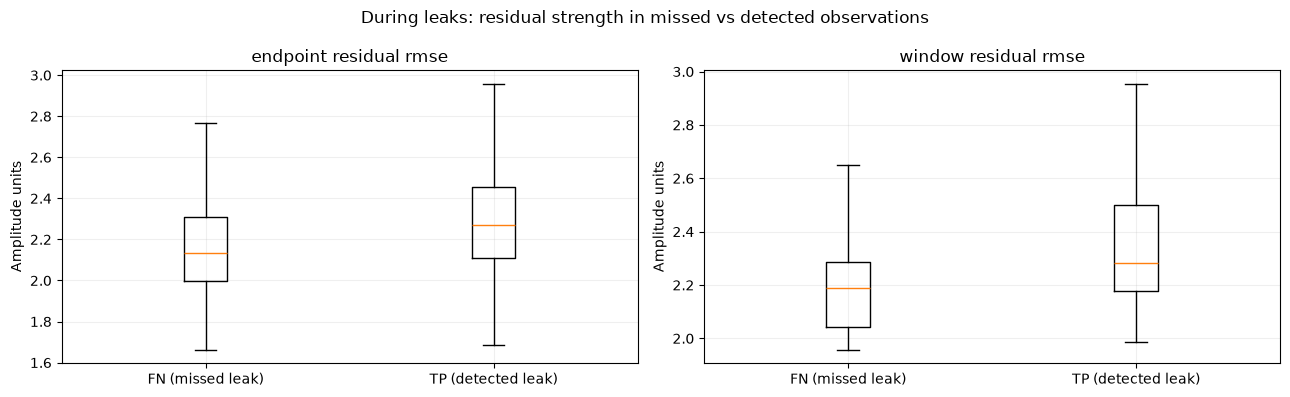

In [8]:
leaking = results[results.true_leak.eq(1)]
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for ax, metric in zip(axes, ["endpoint_residual_rmse", "window_residual_rmse"]):
    ax.boxplot([leaking.loc[leaking.error_type.eq("FN"),metric], leaking.loc[leaking.error_type.eq("TP"),metric]], tick_labels=["FN (missed leak)","TP (detected leak)"], showfliers=False)
    ax.set_title(metric.replace("_", " ")); ax.set_ylabel("Amplitude units"); ax.grid(alpha=.2)
fig.suptitle("During leaks: residual strength in missed vs detected observations")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / f"{EXPERIMENT}_leak_fn_vs_tp.png", dpi=160); plt.show()

## 4. Reynolds dependence and transitions

Plot healthy residual RMSE and false-positive rate across Reynolds bins, and compare stable versus changing Reynolds. Bin statistics are descriptive; small bins and overlapping windows may be unstable. `delta_Reynolds` is the difference between consecutive *observations*, not the difference between adjacent 40-step windows.

,healthy_n,fp_n,median_endpoint_rmse,median_window_rmse,median_abs_delta_Re,fp_rate
Re_bin,,,,,,
<10,1140,22,2.0648,2.0988,0.0000,0.0193
10–25,1521,109,2.1113,2.1435,0.0208,0.0717
25–50,1500,53,2.0977,2.1077,0.0417,0.0353
50–75,1050,127,2.2650,2.2634,0.0000,0.1210
75–100,450,42,2.8981,2.9189,0.0833,0.0933
100–125,1052,99,2.5030,2.4084,0.0000,0.0941
125–150,448,14,2.8694,2.7769,0.0833,0.0312
>150,601,10,2.6158,2.6788,0.0000,0.0166


|delta_Re| quantiles: {0.0: 0.0, 0.5: 0.0, 0.9: 0.0833362340927124, 0.95: 0.1666635274887085, 0.99: 0.1666724681854248, 1.0: 0.1666724681854248}


,n,fp,median_rmse,fp_rate
Re_changing,,,,
False,3901,165,2.191644,0.042297
True,3861,311,2.335119,0.080549


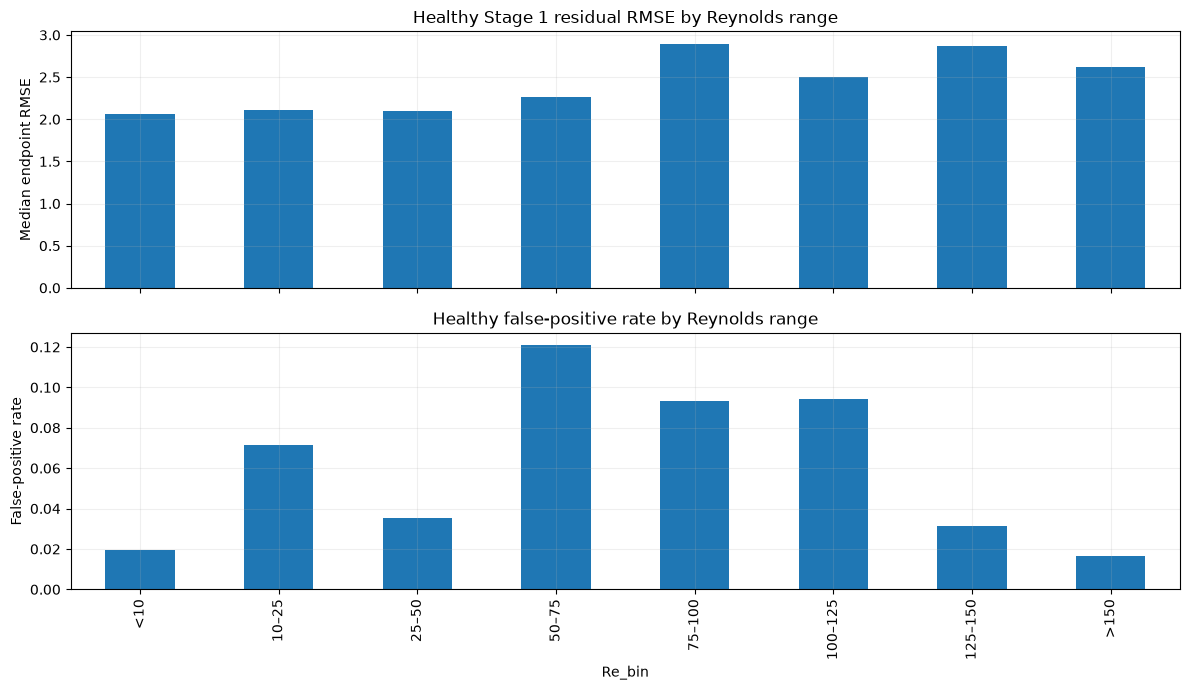

In [9]:
# Report Reynolds bins without silently discarding out-of-range observations.
bins = [-np.inf,10,25,50,75,100,125,150,np.inf]
labels = ["<10","10–25","25–50","50–75","75–100","100–125","125–150",">150"]
healthy["Re_bin"] = pd.cut(healthy.Reynolds, bins=bins, labels=labels, right=False)
by_re = healthy.groupby("Re_bin", observed=False).agg(
    healthy_n=("true_leak","size"), fp_n=("predicted_leak","sum"),
    median_endpoint_rmse=("endpoint_residual_rmse","median"),
    median_window_rmse=("window_residual_rmse","median"),
    median_abs_delta_Re=("abs_delta_Reynolds","median"))
by_re["fp_rate"] = by_re.fp_n / by_re.healthy_n.replace(0,np.nan)
display(by_re.round(4))
# Inspect the transition definition rather than presuming any particular Re scale.
print("|delta_Re| quantiles:", healthy.abs_delta_Reynolds.quantile([0,.5,.9,.95,.99,1]).to_dict())
TRANSITION_THRESHOLD = 0.0   # >0 means any observed change; modify if sensor jitter requires a tolerance
healthy["Re_changing"] = healthy.abs_delta_Reynolds > TRANSITION_THRESHOLD
transition_summary = healthy.groupby("Re_changing").agg(n=("true_leak","size"), fp=("predicted_leak","sum"), median_rmse=("endpoint_residual_rmse","median"))
transition_summary["fp_rate"] = transition_summary.fp / transition_summary.n
display(transition_summary)
fig, axes = plt.subplots(2,1,figsize=(12,7),sharex=True)
by_re["median_endpoint_rmse"].plot.bar(ax=axes[0], title="Healthy Stage 1 residual RMSE by Reynolds range", ylabel="Median endpoint RMSE")
by_re["fp_rate"].plot.bar(ax=axes[1], title="Healthy false-positive rate by Reynolds range", ylabel="False-positive rate")
for ax in axes:ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUTPUT_DIR / f"{EXPERIMENT}_healthy_reynolds_bins.png",dpi=160);plt.show()

## 5. Time alignment: actual leaks, predicted probability, Stage 1 residual and Reynolds

The four panels share the same time axis. Look for high residuals during healthy false-positive episodes, and compare missed leak intervals with residual strength and Reynolds transitions.

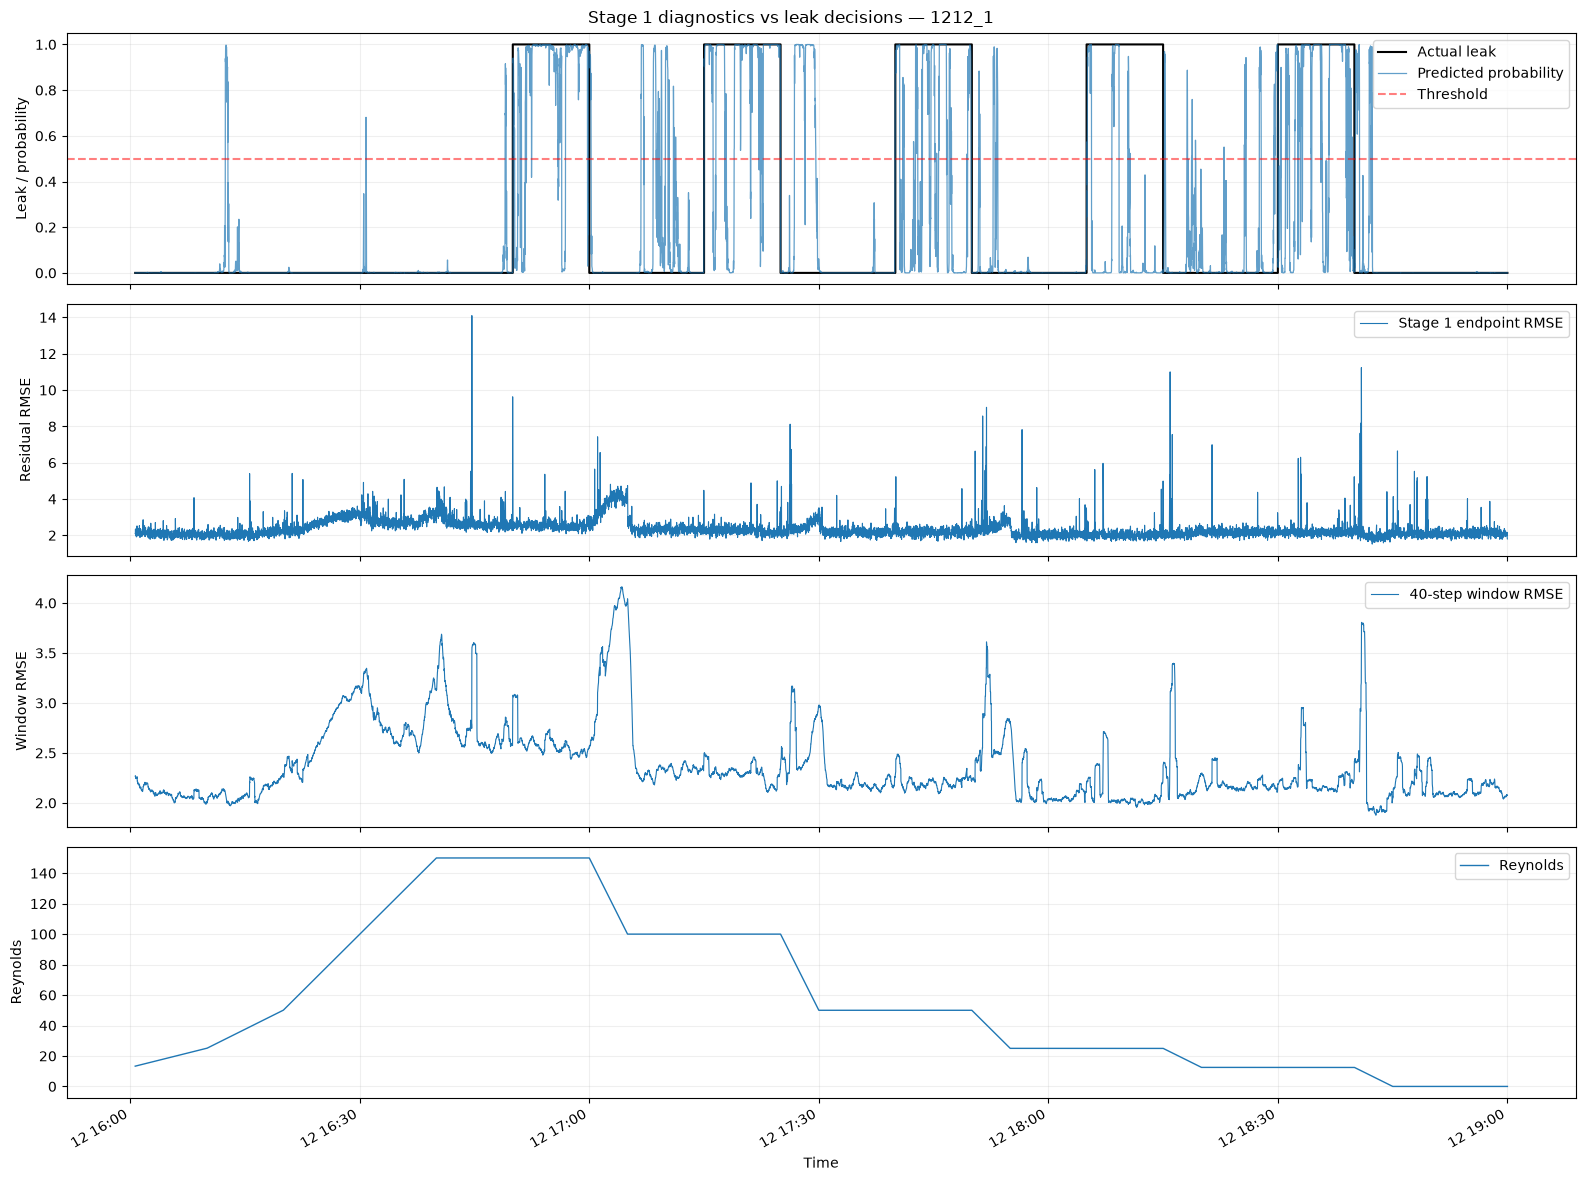

In [10]:
fig, axes = plt.subplots(4,1,figsize=(16,12),sharex=True)
x = results.datetime
axes[0].step(x, results.true_leak, where="post", label="Actual leak", color="black")
axes[0].plot(x, results.predicted_leak_probability, label="Predicted probability", alpha=.7, linewidth=.9)
axes[0].axhline(THRESHOLD,linestyle="--",alpha=.5,color="red",label="Threshold")
axes[0].set_ylabel("Leak / probability");axes[0].legend(loc="upper right")
axes[1].plot(x,results.endpoint_residual_rmse,linewidth=.8,label="Stage 1 endpoint RMSE")
axes[1].set_ylabel("Residual RMSE");axes[1].legend(loc="upper right")
axes[2].plot(x,results.window_residual_rmse,linewidth=.8,label="40-step window RMSE")
axes[2].set_ylabel("Window RMSE");axes[2].legend(loc="upper right")
axes[3].plot(x,results.Reynolds,linewidth=1,label="Reynolds")
axes[3].set_ylabel("Reynolds");axes[3].set_xlabel("Time");axes[3].legend(loc="upper right")
for ax in axes:ax.grid(alpha=.2)
fig.suptitle(f"Stage 1 diagnostics vs leak decisions — {EXPERIMENT}")
fig.autofmt_xdate();fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{EXPERIMENT}_stage1_diagnostic_timeline.png",dpi=160,bbox_inches="tight")
plt.show()

## 6. Per-probe and per-frequency residual diagnostics

To locate where healthy baseline discrepancies occur, calculate endpoint residual RMSE separately for each probe and frequency. These are **descriptive**, not evidence that an individual sensor causes false alarms.

In [11]:
healthy_mask = results.true_leak.to_numpy()==0
fp_mask = results.error_type.to_numpy()=="FP"
tn_mask = results.error_type.to_numpy()=="TN"
rows=[]
for pi, probe in enumerate(PROBE_ORDER):
    for fi, freq in enumerate(sample["frequency_labels"]):
        v = endpoint_residuals[:,pi,fi]
        rows.append({"probe":probe,"frequency":str(freq),
                     "healthy_rmse":float(np.sqrt(np.mean(v[healthy_mask]**2))),
                     "fp_rmse":float(np.sqrt(np.mean(v[fp_mask]**2))) if fp_mask.any() else np.nan,
                     "tn_rmse":float(np.sqrt(np.mean(v[tn_mask]**2))) if tn_mask.any() else np.nan})
probe_freq = pd.DataFrame(rows)
probe_summary = probe_freq.groupby("probe")[["healthy_rmse","fp_rmse","tn_rmse"]].mean()
display(probe_summary.round(4))
display(probe_freq.sort_values("fp_rmse",ascending=False).head(15))

,healthy_rmse,fp_rmse,tn_rmse
probe,,,
DDS,1.7477,1.4010,1.7653
DS,2.4820,2.3349,2.4900
US,2.6524,2.4634,2.6611
UUS,1.6661,1.4301,1.6761


,probe,frequency,healthy_rmse,fp_rmse,tn_rmse
64,DS,f250,9.307666,9.922235,9.266097
32,US,f80,6.728928,7.718313,6.659177
28,US,f31_5,5.152392,5.432278,5.133576
33,US,f100,4.019747,4.423687,3.991935
31,US,f63,4.144734,4.412449,4.126640
36,US,f200,3.653883,4.230999,3.612973
29,US,f40,4.450915,4.223542,4.465367
30,US,f50,5.226322,4.099512,5.291594
86,DDS,f80,2.716979,3.598601,2.649192
54,DS,f25,3.458327,3.586434,3.449792


## 7. Save all diagnostic results

Outputs include the per-observation CSV, summary tables, per-probe/frequency results, and all figures. The full 40×4×27 residual tensors are **not** saved (to avoid enormous overlapping data files); endpoint residuals and window summary statistics are retained.

In [13]:
results.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_stage1_diagnostics.csv",index=False)
summary.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_error_type_summary.csv")
by_re.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_healthy_reynolds_summary.csv")
transition_summary.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_reynolds_transition_summary.csv")
probe_freq.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_probe_frequency_residuals.csv",index=False)
print("Saved outputs to:",OUTPUT_DIR)
print("IMPORTANT: Healthy residual differences are ASSOCIATIONS, not proof that Stage 1 causes false positives.")

Saved outputs to: /home/ubuntu/notebooks/Leak_Detection/data/stage1_diagnostics
IMPORTANT: Healthy residual differences are ASSOCIATIONS, not proof that Stage 1 causes false positives.


## Interpretation checklist

- **FP residuals much larger than TN residuals:** consistent with Stage 1 baseline mismatch contributing to false alarms, but Stage 2 may also be reacting appropriately to unusual *healthy* acoustics.
- **FP and TN residuals similar:** simple residual magnitude does not explain the false alarms; examine frequency/probe patterns and Stage 2 behavior.
- **FN residuals smaller than TP residuals:** missed leaks may have weaker spectral evidence; do not call this Stage 1 error without independent healthy reference measurements.
- **FN residuals comparable to TP residuals:** Stage 2 may be misinterpreting available leak evidence.
- **Healthy residuals spike during Reynolds transitions:** investigate Stage 1 flow-history tracking and baseline fidelity.
- **No clear differences:** the aggregate RMSE may hide sign, frequency, probe, or temporal-pattern information.

**Limits:** This analysis uses the original validation run, one-second overlapping windows, and a fixed 0.5 threshold. It does not independently establish overfitting, calibration, or causal attribution. No new model is trained.